# Replicación sencilla del PCA de Brereton

**Artículo:** Brereton, R. G. (2023). *Principal components analysis with several objects and variables*. *Journal of Chemometrics*, 37, e3408. https://doi.org/10.1002/cem.3408

**Problema:** se tienen 20 muestras y 5 variables. Las primeras 10 muestras forman el grupo azul y las últimas 10, el rojo. Queremos visualizar si los grupos se distinguen y qué variables explican sus diferencias.

**Objetivo:** calcular el PCA con Python y reproducir las **Figuras 1 a 9** y las **Tablas 2 y 3** del artículo. El artículo utiliza los datos **sin centrar**: respetaremos esa decisión para que los números coincidan.

## 1. Carga de datos

El archivo debe estar en `datos/datos_tabla1.csv`. Las figuras se guardarán en `figures/` y las tablas calculadas en `results/`. No se modificará el archivo original.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

datos = pd.read_csv("datos/datos_tabla1.csv")
columnas = datos.columns.tolist()
X = datos.to_numpy()
grupos = np.array(["Azul"] * 10 + ["Rojo"] * 10)
colores = {"Azul": "tab:blue", "Rojo": "tab:red"}
assert X.shape == (20, 5)
display(datos.head())

,x1,x2,x3,x4,x5
0,45.572,53.001,15.800,55.109,21.450
1,49.772,67.859,42.800,45.208,26.778
2,95.976,86.187,63.811,86.309,95.088
3,12.253,16.938,13.518,17.631,17.767
4,87.679,99.045,57.718,69.096,66.729


**Resultado.** Son 20 filas y 5 columnas numéricas. El grupo no se usa para calcular PCA: únicamente sirve para colorear las figuras y comprobar si existe separación visual.

## 2. Figuras del artículo

### Figura 1. Gráficos por parejas de variables

Se comparan todas las parejas de las cinco variables. Si los grupos pudieran separarse fácilmente con una o dos variables originales, se observarían conjuntos de puntos claramente diferenciados.

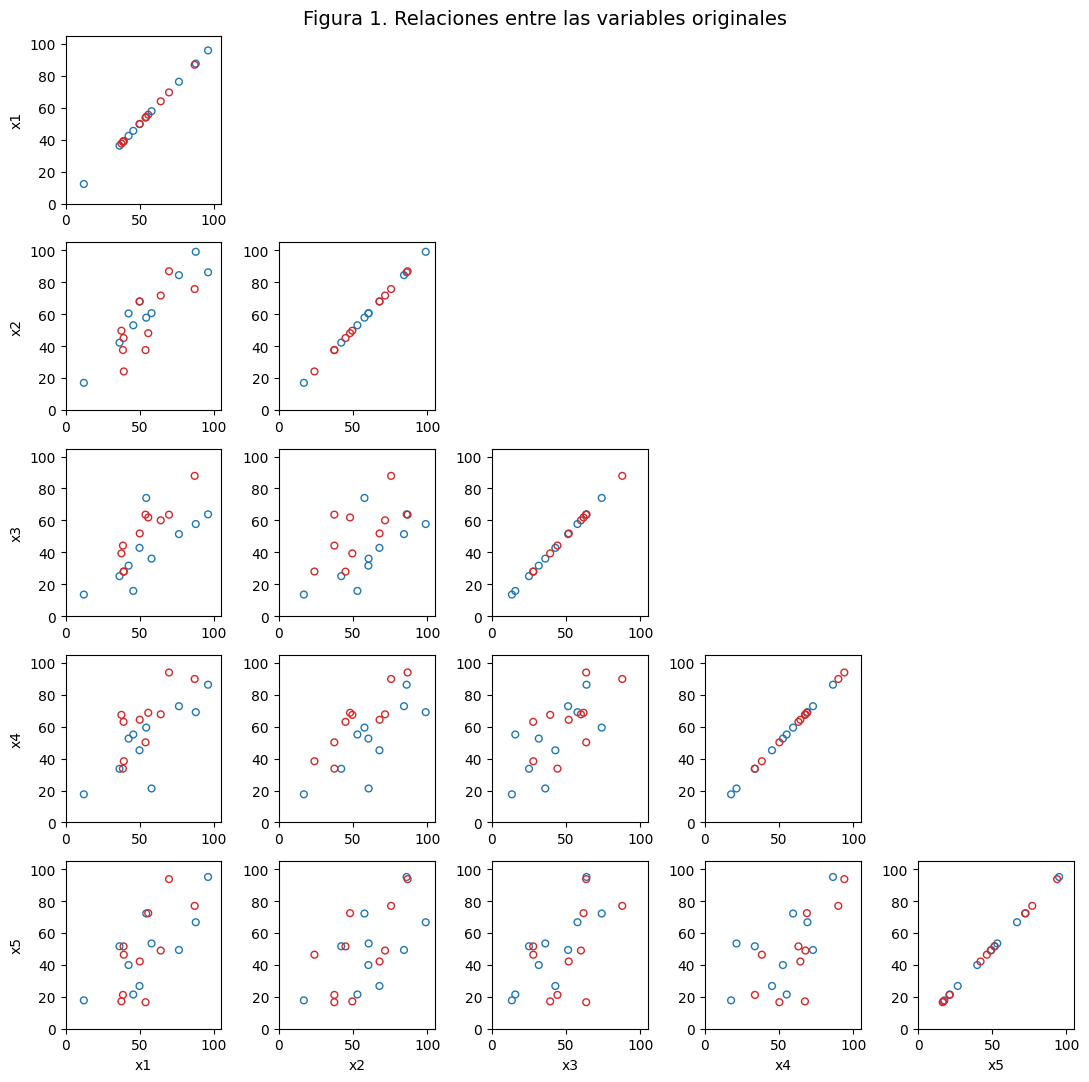

In [2]:
fig, ejes = plt.subplots(5, 5, figsize=(11, 11))
for i in range(5):
    for j in range(5):
        ax = ejes[i, j]
        if j > i:
            ax.axis("off")
            continue
        for grupo in ["Azul", "Rojo"]:
            filtro = grupos == grupo
            ax.scatter(X[filtro, j], X[filtro, i], s=24, facecolors="none", edgecolors=colores[grupo])
        ax.set_xlim(0, 105)
        ax.set_ylim(0, 105)
        if i == 4:
            ax.set_xlabel(columnas[j])
        if j == 0:
            ax.set_ylabel(columnas[i])
fig.suptitle("Figura 1. Relaciones entre las variables originales", fontsize=14)
fig.tight_layout()
fig.savefig("figures/figura_01_variables.png", dpi=170)
plt.show()

**Interpretación.** Los puntos de ambos grupos se superponen en muchas proyecciones. Los gráficos de parejas no ofrecen una separación convincente, como señala el artículo.

### Figura 2. Cada variable por separado

Se representa cada variable sobre una sola recta, sin combinarla con las demás.

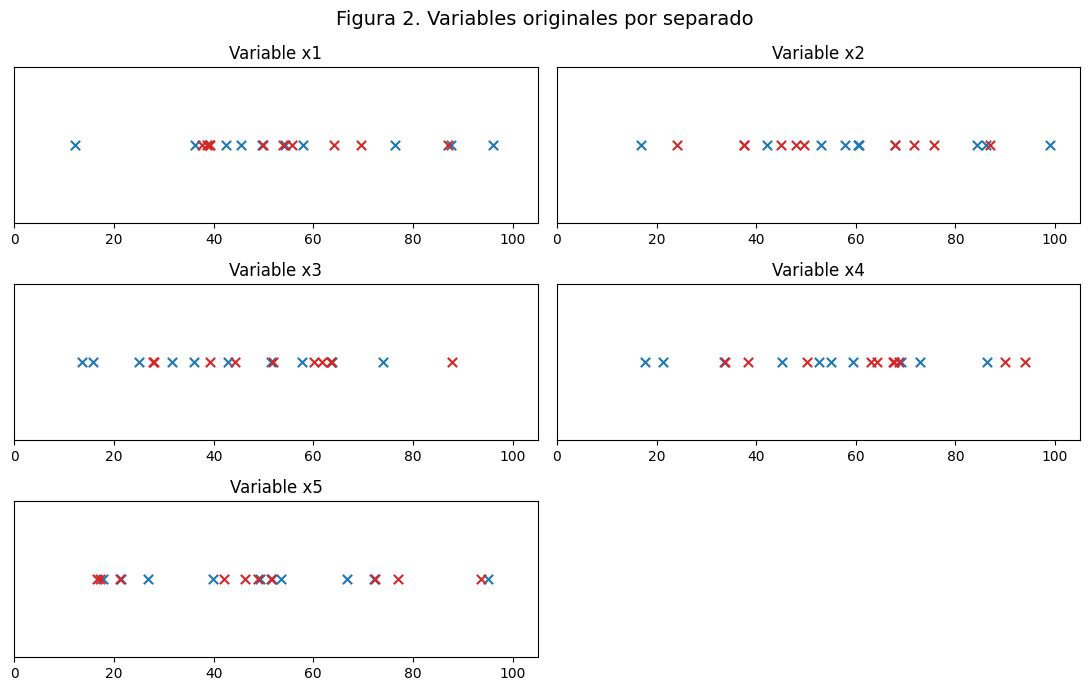

In [3]:
fig, ejes = plt.subplots(3, 2, figsize=(11, 7))
for i, nombre in enumerate(columnas):
    ax = ejes.flat[i]
    for grupo in ["Azul", "Rojo"]:
        filtro = grupos == grupo
        ax.scatter(X[filtro, i], np.zeros(filtro.sum()), marker="x", color=colores[grupo], s=45)
    ax.set_title(f"Variable {nombre}")
    ax.set_xlim(0, 105)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
ejes.flat[-1].axis("off")
fig.suptitle("Figura 2. Variables originales por separado", fontsize=14)
fig.tight_layout()
fig.savefig("figures/figura_02_univariadas.png", dpi=170)
plt.show()

**Interpretación.** Ninguna variable individual distingue perfectamente los dos grupos. Por eso resulta útil proyectar conjuntamente las cinco variables.

## 3. Cálculo del PCA

El artículo calcula **PCA sin centrar**. Para reproducirlo utilizamos la descomposición en valores singulares: $X = U\Sigma V^T$.

Los **scores** se calculan como $T = U\Sigma$, las **cargas** como $P = V^T$ y los **valores propios del artículo** como $g_a = \sum_i t_{ia}^2 = \sigma_a^2$.

Los signos de las componentes son arbitrarios: elegimos la orientación de la Tabla 2 para comparar directamente, sin alterar el resultado del PCA.

In [4]:
U, s, Vt = np.linalg.svd(X, full_matrices=False)
orientacion = np.where(Vt[np.arange(5), [0, 4, 2, 3, 0]] < 0, -1, 1)
T = (U * s) * orientacion
P = Vt * orientacion[:, None]
autovalores = s ** 2
porcentajes = 100 * autovalores / autovalores.sum()
componentes = [f"PC{i}" for i in range(1, 6)]

scores = pd.DataFrame(T, index=range(1, 21), columns=componentes)
loadings = pd.DataFrame(P, index=componentes, columns=columnas)
valores = pd.DataFrame({"PC": componentes, "Autovalor": autovalores, "Porcentaje": porcentajes, "Acumulado": np.cumsum(porcentajes)})

scores.to_csv("results/scores_calculados.csv", index_label="muestra")
loadings.to_csv("results/loadings_calculados.csv", index_label="PC")
valores.to_csv("results/autovalores_calculados.csv", index=False)

display(scores.head().round(3))
display(loadings.round(3))
display(valores.round(3))

,PC1,PC2,PC3,PC4,PC5
1,87.987,-20.011,-14.934,14.275,7.978
2,105.214,-21.014,-6.840,-8.256,-6.951
3,191.584,16.512,-9.576,-1.073,11.505
4,34.950,3.131,0.127,2.486,-2.965
5,171.604,-8.600,-19.651,-12.148,0.651


,x1,x2,x3,x4,x5
PC1,0.457,0.486,0.392,0.477,0.418
PC2,-0.135,-0.389,-0.053,-0.207,0.886
PC3,-0.144,-0.566,0.756,0.242,-0.169
PC4,-0.395,-0.126,-0.417,0.807,0.049
PC5,0.772,-0.525,-0.313,0.140,-0.099


,PC,Autovalor,Porcentaje,Acumulado
0,PC1,320295.793,96.550,96.550
1,PC2,4724.306,1.424,97.975
2,PC3,3498.699,1.055,99.029
3,PC4,2489.835,0.751,99.780
4,PC5,730.796,0.220,100.000


**Interpretación.** El primer componente domina la suma de cuadrados porque los datos no están centrados y todas las variables son positivas. Su porcentaje **no debe confundirse con la varianza explicada de un PCA centrado**, ya que incorpora el nivel medio de las mediciones.

## 4. Comparación con las tablas publicadas

Las tablas originales se transcribieron a los CSV de la carpeta `datos/`. Compararemos los 100 scores, las 25 cargas y los 5 autovalores, sin sustituir los valores calculados por los publicados.

In [5]:
scores_articulo = pd.read_csv("datos/tabla2_scores_publicados.csv", index_col="muestra")
loadings_articulo = pd.read_csv("datos/tabla2_loadings_publicados.csv", index_col="PC")
valores_articulo = pd.read_csv("datos/tabla3_autovalores_publicados.csv")

comparacion_valores = valores_articulo.copy()
comparacion_valores["Calculado"] = autovalores
comparacion_valores["Diferencia"] = comparacion_valores["Calculado"] - comparacion_valores["articulo"]
comparacion_scores = pd.concat({"Articulo": scores_articulo, "Calculado": scores}, axis=1)
comparacion_loadings = pd.concat({"Articulo": loadings_articulo, "Calculado": loadings}, axis=1)

comparacion_valores.to_csv("results/comparacion_autovalores.csv", index=False)
comparacion_scores.to_csv("results/comparacion_scores.csv", index_label="muestra")
comparacion_loadings.to_csv("results/comparacion_loadings.csv", index_label="PC")

display(comparacion_valores.round(3))
print("Mayor diferencia en scores:", round(np.abs(scores - scores_articulo).to_numpy().max(), 6))
print("Mayor diferencia en loadings:", round(np.abs(loadings - loadings_articulo).to_numpy().max(), 6))
print("Mayor diferencia en autovalores:", round(np.abs(comparacion_valores["Diferencia"]).max(), 6))
assert np.abs(scores - scores_articulo).to_numpy().max() < 0.003
assert np.abs(loadings - loadings_articulo).to_numpy().max() < 0.001
assert np.abs(comparacion_valores["Diferencia"]).max() < 5

,PC,articulo,Calculado,Diferencia
0,PC1,320300,320295.793,-4.207
1,PC2,4720,4724.306,4.306
2,PC3,3500,3498.699,-1.301
3,PC4,2490,2489.835,-0.165
4,PC5,730,730.796,0.796


Mayor diferencia en scores: 0.001167
Mayor diferencia en loadings: 0.000477
Mayor diferencia en autovalores: 4.305796


**Resultado.** Las diferencias pequeñas se explican por el redondeo de las tablas: los scores y las cargas se publicaron con tres decimales, mientras que los autovalores se redondearon a centenas o decenas. Las comprobaciones automáticas confirman la concordancia.

### Figura 3. Comparaciones entre scores

Ahora cada muestra se representa mediante sus puntuaciones en las componentes principales. Se observan todas las combinaciones de componentes.

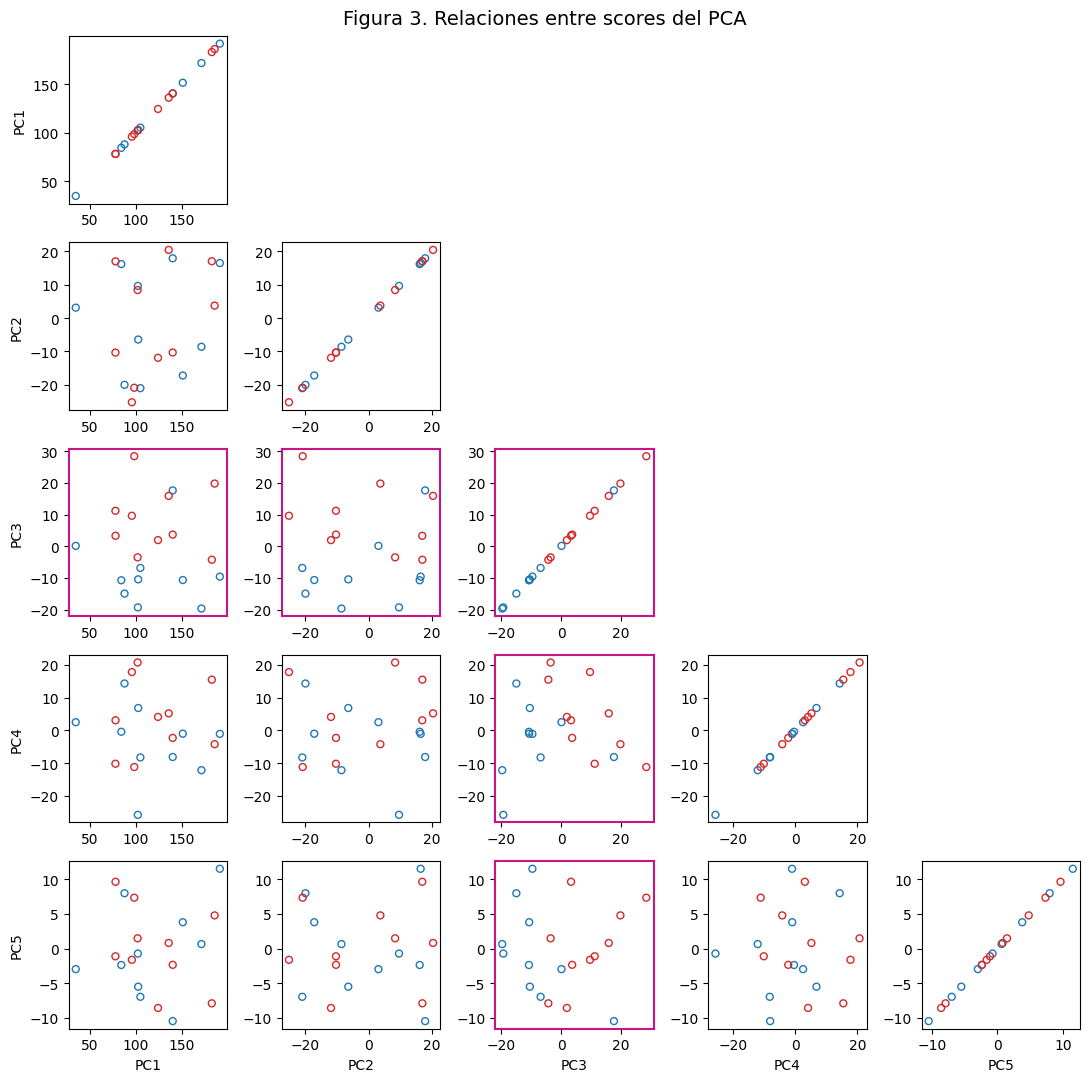

In [6]:
fig, ejes = plt.subplots(5, 5, figsize=(11, 11))
for i in range(5):
    for j in range(5):
        ax = ejes[i, j]
        if j > i:
            ax.axis("off")
            continue
        for grupo in ["Azul", "Rojo"]:
            filtro = grupos == grupo
            ax.scatter(T[filtro, j], T[filtro, i], s=25, facecolors="none", edgecolors=colores[grupo])
        if i == 2 or j == 2:
            for borde in ax.spines.values():
                borde.set_edgecolor("mediumvioletred")
                borde.set_linewidth(1.5)
        if i == 4:
            ax.set_xlabel(componentes[j])
        if j == 0:
            ax.set_ylabel(componentes[i])
fig.suptitle("Figura 3. Relaciones entre scores del PCA", fontsize=14)
fig.tight_layout()
fig.savefig("figures/figura_03_scores.png", dpi=170)
plt.show()

**Interpretación.** Las proyecciones que incluyen **PC3** muestran una separación más clara entre los grupos. Esto no implica que PC3 explique la mayor parte de la energía de los datos: identifica una diferencia útil entre grupos.

### Figura 4. PC3 frente a PC1

Se destaca la proyección que utiliza PC1 en el eje horizontal y PC3 en el vertical.

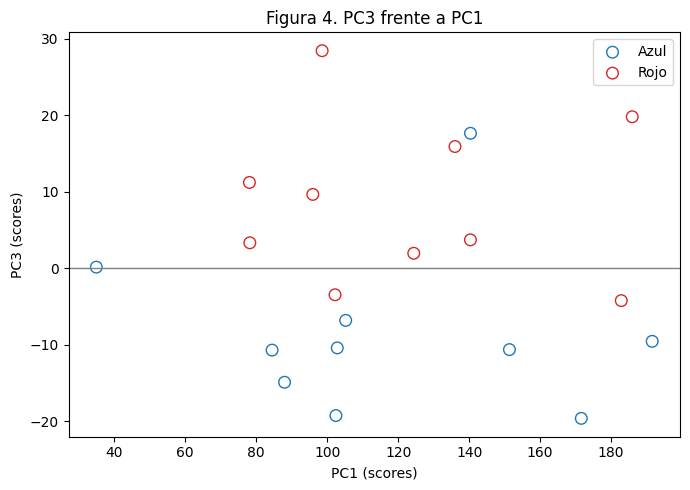

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for grupo in ["Azul", "Rojo"]:
    filtro = grupos == grupo
    ax.scatter(T[filtro, 0], T[filtro, 2], s=70, facecolors="none", edgecolors=colores[grupo], label=grupo)
ax.axhline(0, color="gray", linewidth=1)
ax.set_xlabel("PC1 (scores)")
ax.set_ylabel("PC3 (scores)")
ax.set_title("Figura 4. PC3 frente a PC1")
ax.legend()
fig.tight_layout()
fig.savefig("figures/figura_04_pc3_vs_pc1.png", dpi=170)
plt.show()

**Interpretación.** La separación aparece principalmente en el eje vertical, **PC3**. PC1 recoge sobre todo la magnitud total de las observaciones.

### Figura 5. Scores de PC3

Eliminamos PC1 y miramos únicamente la tercera componente.

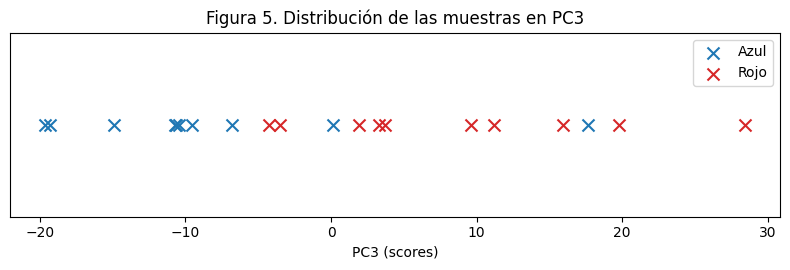

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for grupo in ["Azul", "Rojo"]:
    filtro = grupos == grupo
    ax.scatter(T[filtro, 2], np.zeros(filtro.sum()), marker="x", s=75, color=colores[grupo], label=grupo)
ax.set_yticks([])
ax.set_xlabel("PC3 (scores)")
ax.set_title("Figura 5. Distribución de las muestras en PC3")
ax.legend()
fig.tight_layout()
fig.savefig("figures/figura_05_pc3_univariada.png", dpi=170)
plt.show()

**Interpretación.** Los scores de PC3 tienden a ser negativos para el grupo azul y positivos para el rojo, aunque existe superposición. PCA es exploratorio: **no equivale a un clasificador perfecto**.

### Figura 6. PC1 y suma de intensidades

El artículo relaciona los scores de PC1 con la suma de cada fila, y las cargas de PC1 con la suma de cada columna.

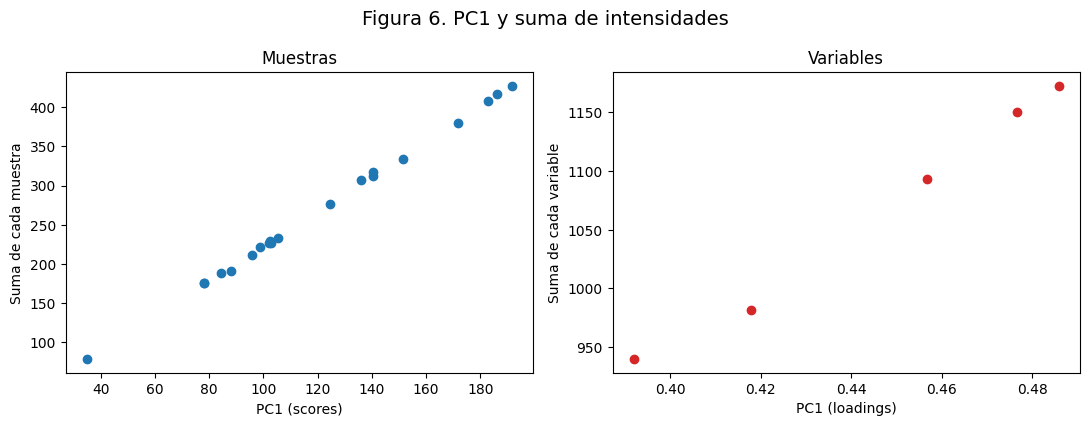

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.3))
ejes[0].scatter(T[:, 0], X.sum(axis=1), color="tab:blue")
ejes[0].set_xlabel("PC1 (scores)")
ejes[0].set_ylabel("Suma de cada muestra")
ejes[0].set_title("Muestras")
ejes[1].scatter(P[0], X.sum(axis=0), color="tab:red")
ejes[1].set_xlabel("PC1 (loadings)")
ejes[1].set_ylabel("Suma de cada variable")
ejes[1].set_title("Variables")
fig.suptitle("Figura 6. PC1 y suma de intensidades", fontsize=14)
fig.tight_layout()
fig.savefig("figures/figura_06_intensidades.png", dpi=170)
plt.show()

**Interpretación.** Las relaciones son casi lineales: PC1 se asocia con la **intensidad global** de cada muestra y de cada variable. Esto ayuda a entender por qué PC1 es tan grande en el PCA sin centrar.

### Figura 7. Cargas de PC1, PC2 y PC3

Las cargas indican qué variables contribuyen a cada componente.

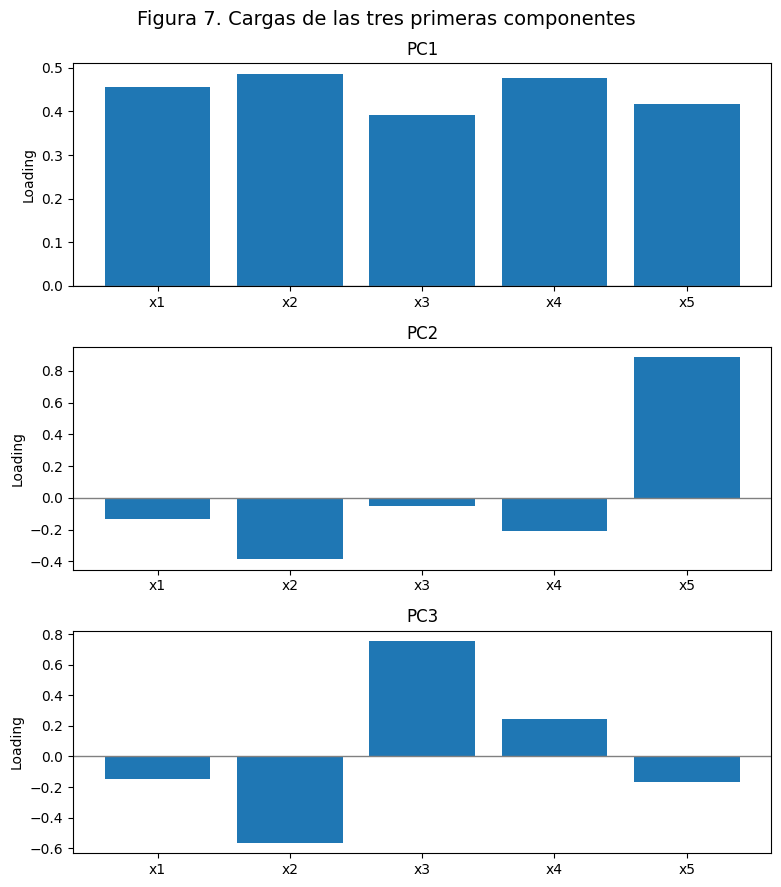

In [10]:
fig, ejes = plt.subplots(3, 1, figsize=(8, 9))
for i, ax in enumerate(ejes):
    ax.bar(columnas, P[i], color="tab:blue")
    ax.axhline(0, color="gray", linewidth=1)
    ax.set_ylabel("Loading")
    ax.set_title(f"PC{i+1}")
fig.suptitle("Figura 7. Cargas de las tres primeras componentes", fontsize=14)
fig.tight_layout()
fig.savefig("figures/figura_07_loadings.png", dpi=170)
plt.show()

**Interpretación.** En PC3, **x2 tiene una carga negativa** y **x3 una positiva**. Esta diferencia permite interpretar por qué las muestras de ambos grupos tienden a situarse en lados distintos de PC3.

### Figura 8. Cargas de PC3 frente a PC1

Cada punto es una variable original: se etiqueta de x1 a x5.

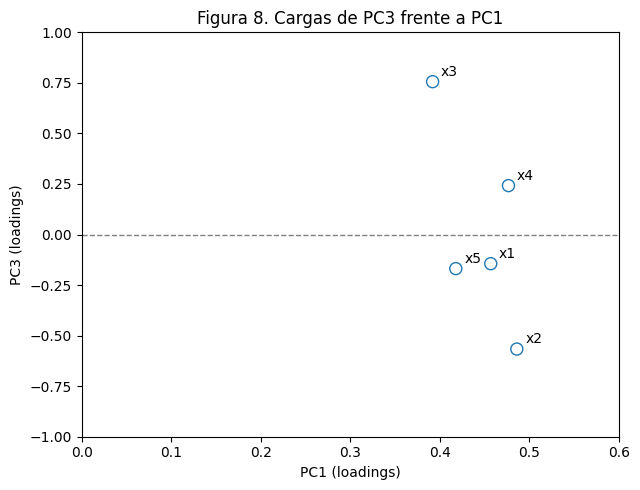

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(P[0], P[2], s=75, facecolors="none", edgecolors="tab:blue")
for i, nombre in enumerate(columnas):
    ax.annotate(nombre, (P[0, i], P[2, i]), xytext=(6, 4), textcoords="offset points")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlim(0, 0.6)
ax.set_ylim(-1, 1)
ax.set_xlabel("PC1 (loadings)")
ax.set_ylabel("PC3 (loadings)")
ax.set_title("Figura 8. Cargas de PC3 frente a PC1")
fig.tight_layout()
fig.savefig("figures/figura_08_loadings_pc3_pc1.png", dpi=170)
plt.show()

**Interpretación.** x2 aparece abajo por su relación negativa con PC3 y x3 arriba por su relación positiva. Es coherente con la separación de muestras observada en la Figura 4.

### Figura 9. Cargas de PC3 frente a PC2

Se estudia la relación de las variables originales con dos componentes que no son PC1.

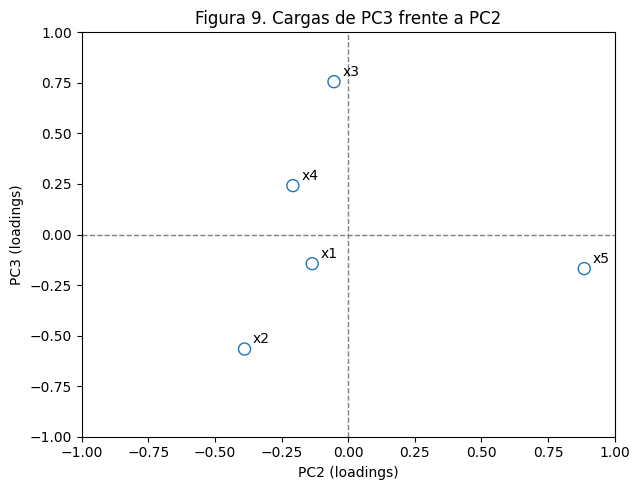

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(P[1], P[2], s=75, facecolors="none", edgecolors="tab:blue")
for i, nombre in enumerate(columnas):
    ax.annotate(nombre, (P[1, i], P[2, i]), xytext=(6, 4), textcoords="offset points")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_xlabel("PC2 (loadings)")
ax.set_ylabel("PC3 (loadings)")
ax.set_title("Figura 9. Cargas de PC3 frente a PC2")
fig.tight_layout()
fig.savefig("figures/figura_09_loadings_pc3_pc2.png", dpi=170)
plt.show()

**Interpretación.** Las variables **x1** y **x4** aparecen próximas al origen respecto de PC2 y PC3: tienen un papel relativamente pequeño en estas dos componentes. La separación se relaciona más con x2 y x3.

## 5. Comprobación final

Verificamos que los scores y las cargas permiten reconstruir la matriz original. Mostramos además dónde se guardaron los resultados del ejercicio.

In [13]:
error_reconstruccion = np.max(np.abs(X - T @ P))
resumen = pd.DataFrame({
    "Comprobacion": ["Reconstruccion de X", "Scores frente al articulo", "Loadings frente al articulo"],
    "Error maximo": [error_reconstruccion, np.abs(scores - scores_articulo).to_numpy().max(), np.abs(loadings - loadings_articulo).to_numpy().max()]
})
resumen.to_csv("results/resumen_validacion.csv", index=False)
display(resumen)
print("Figuras guardadas:", len(list(Path("figures").glob("*.png"))))
print("Tablas guardadas:", len(list(Path("results").glob("*.csv"))))

,Comprobacion,Error maximo
0,Reconstruccion de X,1.989520e-13
1,Scores frente al articulo,1.166505e-03
2,Loadings frente al articulo,4.768228e-04


Figuras guardadas: 9
Tablas guardadas: 7


**Conclusión.** Con los datos de la Tabla 1 se reproducen las Figuras 1–9 y los resultados numéricos de las Tablas 2 y 3. El aspecto decisivo es **respetar el procesamiento del artículo**: aquí se trabaja sin centrar los datos.

**Referencia:** Brereton, R. G. (2023). *Principal components analysis with several objects and variables*. *Journal of Chemometrics*, 37, e3408. https://doi.org/10.1002/cem.3408

**Nota:** las figuras son reconstrucciones realizadas con Python, no reproducciones de imágenes del PDF.